# Preparació de l'entorn de treball

In [ ]:
!pip -q install geopandas pyogrio requests

In [1]:
# Importació de llibreries
import os
import re
import zipfile
import requests
import pandas as pd
import geopandas as gpd
import xml.etree.ElementTree as ET

from pathlib import Path
from urllib.parse import urljoin

print("Entorn preparat correctament")

Entorn preparat correctament


# Preparació de les dades

In [2]:
# Catàleg de municipis
municipis = [
    ("Badalona", "08015"),
    ("Badia del Vallès", "08904"),
    ("Barberà del Vallès", "08252"),
    ("Barcelona", "08019"),
    ("Begues", "08020"),
    ("Castellbisbal", "08054"),
    ("Castelldefels", "08056"),
    ("Cerdanyola del Vallès", "08266"),
    ("Cervelló", "08068"),
    ("Corbera de Llobregat", "08072"),
    ("Cornellà de Llobregat", "08073"),
    ("El Papiol", "08158"),
    ("El Prat de Llobregat", "08169"),
    ("Esplugues de Llobregat", "08077"),
    ("Gavà", "08089"),
    ("L'Hospitalet de Llobregat", "08101"),
    ("La Palma de Cervelló", "08905"),
    ("Molins de Rei", "08123"),
    ("Montcada i Reixac", "08125"),
    ("Montgat", "08126"),
    ("Pallejà", "08157"),
    ("Ripollet", "08180"),
    ("Sant Adrià de Besòs", "08194"),
    ("Sant Andreu de la Barca", "08196"),
    ("Sant Boi de Llobregat", "08200"),
    ("Sant Climent de Llobregat", "08204"),
    ("Sant Cugat del Vallès", "08205"),
    ("Sant Feliu de Llobregat", "08211"),
    ("Sant Joan Despí", "08217"),
    ("Sant Just Desvern", "08221"),
    ("Sant Vicenç dels Horts", "08263"),
    ("Santa Coloma de Cervelló", "08244"),
    ("Santa Coloma de Gramenet", "08245"),
    ("Tiana", "08282"),
    ("Torrelles de Llobregat", "08289"),
    ("Viladecans", "08301")
]

df_municipis = pd.DataFrame(
    municipis,
    columns=["municipi", "codi_ine"]
)

assert len(df_municipis) == 36
assert df_municipis["codi_ine"].is_unique

display(df_municipis)

,municipi,codi_ine
0,Badalona,08015
1,Badia del Vallès,08904
2,Barberà del Vallès,08252
3,Barcelona,08019
4,Begues,08020
5,Castellbisbal,08054
6,Castelldefels,08056
7,Cerdanyola del Vallès,08266
8,Cervelló,08068
9,Corbera de Llobregat,08072


In [3]:
print("Dimensions:", df_municipis.shape)

print(
    "Codis INE duplicats:",
    df_municipis["codi_ine"].duplicated().sum()
)

print(
    "Municipis:",
    df_municipis["municipi"].nunique()
)

Dimensions: (36, 2)
Codis INE duplicats: 0
Municipis: 36


# Adquisició de les dades del Cadastre INSPIRE

## Consulta del catàleg
El Cadastre publica un catàleg en format ATOM, un estàndard de sindicació de continguts basat en XML. En el catàleg publiquen els enllaços als conjunts de dades geogràfiques.

### Llibreries utilitzades
`requests` : permet fer peticions HTTP a servidors web

`xml.etree.ElementTree as ET` : permet llegir i navegar per documents XML

## Petició al servidor
Es defineix un url de petició dels edificis del cadastre (tots).

`requests.get(url)` envia la petició GET al servidor del cadastre. El resultat, un objecte de tipus `Response`, es guarda a la variable `response`.

El resultat presenta diferents propietats, com per exemple:
- `response.status_code`. Codi HTTP de resposta
- `response.content`. Contingut rebut en format binari
- `response.text`. Contingut rebut interpretat com a text
- `response.headers`. Capçaleres de la resposta

In [4]:
import requests
import xml.etree.ElementTree as ET

# Servei ATOM d'edificis del Cadastre
url = "https://www.catastro.hacienda.gob.es/INSPIRE/buildings/ES.SDGC.BU.atom.xml"

response = requests.get(url)
response.raise_for_status()

print("Codi de resposta:", response.status_code)
print("Mida del catàleg:", len(response.content), "bytes")

Codi de resposta: 200
Mida del catàleg: 682565 bytes


## Lectura del document XML rebut
`ET.fromstring()` interpreta el contingut XML i construeix un arbre d'elements amb estructura navegable.

Un cop desat com a element navegable, es poden buscar elements. Per fer-ho, es fa ús de l'espai de noms.

En XML, els espais de noms (namespaces) identifiquen a quin estàndard pertanyen els elements. En aquest cas, l'estàndard és ATOM. El diccionari `ns` associa un àlies (atom) amb l'URI de l'espai de noms.

Per buscar elements s'utilitza la funció `.findall()`. Per buscar els elements anomenats `entry` que pertanyen a l'espai de noms identificat com a `atom` cal introduir `findall("atom:entry", ns)`.

L'arbre que representa l'arxiu XML està estructurat en entrades (`entry`) que pengen directament de `root`. Cada entrada conté diferents elements, com el títol o enllaços.

El catàleg està organitzat per províncies. Es cerca el títol (`title`) de cada entrada per poder filtrar sobre la província de Barcelona. A diferència de `findall()`, que retorna elements XML, `findtext()` retorna directament el contingut textual.

Si coincideix el títol amb la província, es recupera l'enllaç del seu contingut. L'enllaç està definit com a `enclosure`, que indica que l'enllaç està associat al contingut distribuït per aquella entrada. Els enllaços a les dades estan codificades com a `"href"`; el mètode `.attrib` retorna un diccionari amb els atributs de l'element `link`, i el mètode `.get()` permet recuperar el valor de la clau "href".

És a dir, el catàleg general et dirigeix a un catàleg provincial, i no a les geometries directament.

In [5]:
root = ET.fromstring(response.content)

ns = {"atom": "http://www.w3.org/2005/Atom"}

entries = root.findall("atom:entry", ns)
print("Nombre total d'entrades:", len(entries))

barcelona_url = None

for entry in entries:
    title = entry.findtext("atom:title", default="", namespaces=ns)

    if "Barcelona" in title:
      print("\nEntrada trobada:")
      print("Títol:", title)

      for link in entry.findall("atom:link", ns):
        if link.attrib.get("rel") == "enclosure":
          barcelona_url = link.attrib["href"]
          print("Província:", title)
          print("Enllaç:", barcelona_url)

          break


Nombre total d'entrades: 56

Entrada trobada:
Títol: Territorial office 08 Barcelona
Província: Territorial office 08 Barcelona
Enllaç: http://www.catastro.hacienda.gob.es/INSPIRE/buildings/08/ES.SDGC.bu.atom_08.xml


## Lectura del catàleg provincial
Repetició del pas anterior amb el catàleg de la província de Barcelona.

In [6]:
response_bcn = requests.get(barcelona_url)
response_bcn.raise_for_status()

print("Codi de resposta:", response_bcn.status_code)
print("Mida del catàleg:", len(response_bcn.content), "bytes")

root_bcn = ET.fromstring(response_bcn.content)

entries_bcn = root_bcn.findall("atom:entry", ns)

print("Nombre total d'entrades BCN:", len(entries_bcn))

registres_cataleg = []

for entry in entries_bcn:
  titol = entry.findtext("atom:title", default="", namespaces=ns)
  enllaç = next(
      (
          link for link in entry.findall("atom:link", ns)
          if link.get("rel") == "enclosure"
      ),
      None
  )

  registres_cataleg.append({
      "titol_cataleg": titol,
      "href_original": enllaç.get("href") if enllaç is not None else None,
      "tipus": enllaç.get("type") if enllaç is not None else None
  })

df_cataleg = pd.DataFrame(registres_cataleg)

print("Entrades del catàleg:", len(df_cataleg))

display(df_cataleg.head(10))

Codi de resposta: 200
Mida del catàleg: 543609 bytes
Nombre total d'entrades BCN: 311
Entrades del catàleg: 311


,titol_cataleg,href_original,tipus
0,08001-ABRERA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
1,08002-AGUILAR DE SEGARRA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
2,08014-AIGUAFREDA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
3,08003-ALELLA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
4,08004-ALPENS buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
5,08006-ARENYS DE MAR buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
6,08007-ARENYS DE MUNT buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
7,08008-ARGEN OLA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
8,08009-ARGENTONA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml
9,08010-ARTES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml


In [ ]:
registres_cataleg

[{'titol_cataleg': ' 08001-ABRERA buildings',
  'href_original': 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08001-ABRERA/A.ES.SDGC.BU.08001.zip',
  'tipus': 'application/atom+xml'},
 {'titol_cataleg': ' 08002-AGUILAR DE SEGARRA buildings',
  'href_original': 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08002-AGUILAR DE SEGARRA/A.ES.SDGC.BU.08002.zip',
  'tipus': 'application/atom+xml'},
 {'titol_cataleg': ' 08014-AIGUAFREDA buildings',
  'href_original': 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08014-AIGUAFREDA/A.ES.SDGC.BU.08014.zip',
  'tipus': 'application/atom+xml'},
 {'titol_cataleg': ' 08003-ALELLA buildings',
  'href_original': 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08003-ALELLA/A.ES.SDGC.BU.08003.zip',
  'tipus': 'application/atom+xml'},
 {'titol_cataleg': ' 08004-ALPENS buildings',
  'href_original': 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08004-ALPENS/A.ES.SDGC.BU.08004.zip',
  'tipus': 'ap

In [7]:
# Extracció del codi de 5 dígits del títol del catàleg
df_cataleg["codi_cataleg"] = df_cataleg["titol_cataleg"].str.extract(r"(\d{5})")

# Selecció dels codis de l'AMB del catàleg per correspondència
codis_amb = df_municipis["codi_ine"].astype(str)

df_cataleg_amb = df_cataleg[df_cataleg["codi_cataleg"].isin(codis_amb)].copy()

# Incorporació del nom oficial del catàleg a la taula de municipis
df_cataleg_amb = df_municipis.merge(
    df_cataleg_amb,
    left_on="codi_ine",
    right_on="codi_cataleg",
    how="left"
)

print("Entrades trobades:", df_cataleg_amb["href_original"].notna().sum())

display(df_cataleg_amb)

Entrades trobades: 33


,municipi,codi_ine,titol_cataleg,href_original,tipus,codi_cataleg
0,Badalona,08015,08015-BADALONA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08015
1,Badia del Vallès,08904,NaN,NaN,NaN,NaN
2,Barberà del Vallès,08252,08252-BARBERA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08252
3,Barcelona,08019,NaN,NaN,NaN,NaN
4,Begues,08020,08020-BEGUES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08020
5,Castellbisbal,08054,08054-CASTELLCIR buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08054
6,Castelldefels,08056,08056-CASTELL DE L ARENY buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08056
7,Cerdanyola del Vallès,08266,08266-CERDANYOLA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08266
8,Cervelló,08068,08068-COLLBATO buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08068
9,Corbera de Llobregat,08072,08072-CORNELLA DE LLOBREGAT buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...,application/atom+xml,08072


In [8]:
# Masses discrepàncies observades entre els codis INE i els noms dels municipis

# Extracció del nom del municipi del catàleg
df_cataleg_amb["nom_cataleg"] = df_cataleg_amb["titol_cataleg"].str.strip().str.extract(
    r"^\d{5}-(.*?)\s+buildings$", expand=False
)

# Comparativa amb els noms AMB
display(
    df_cataleg_amb[["codi_ine", "municipi", "nom_cataleg"]]
)

,codi_ine,municipi,nom_cataleg
0,08015,Badalona,BADALONA
1,08904,Badia del Vallès,NaN
2,08252,Barberà del Vallès,BARBERA DEL VALLES
3,08019,Barcelona,NaN
4,08020,Begues,BEGUES
5,08054,Castellbisbal,CASTELLCIR
6,08056,Castelldefels,CASTELL DE L ARENY
7,08266,Cerdanyola del Vallès,CERDANYOLA DEL VALLES
8,08068,Cervelló,COLLBATO
9,08072,Corbera de Llobregat,CORNELLA DE LLOBREGAT


### ESTUDI DE LA COHERÈNCIA DEL CATÀLEG
Comparació dels noms dels 36 municipis de l'AMB amb els 311 títols del catàleg de Barcelona.

Cal ignorar accents, majúscules i signes de puntuació.

Revisió dels candiats pels municipis que no coincideixen.

In [9]:
import re
import unicodedata

def normalitza_nom(text):
    if pd.isna(text):
        return None

    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(
        c for c in text
        if not unicodedata.combining(c)
    )
    text = text.upper()

    # Eliminar el codi inicial del catàleg
    text = re.sub(r"^\s*\d{5}\s*-\s*", "", text)

    # Eliminar el sufix buildings
    text = re.sub(r"\s+BUILDINGS\s*$", "", text)

    # Unificar espais i signes de puntuació
    text = re.sub(r"[^A-Z0-9]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


# Aplicar la funció al DF de l'AMB i al del Catàleg
df_municipis["nom_norm"] = df_municipis["municipi"].apply(normalitza_nom)

df_cataleg["nom_norm"] = df_cataleg["titol_cataleg"].apply(normalitza_nom)


coincidencies = df_municipis.merge(
    df_cataleg,
    on="nom_norm",
    how="left",
    suffixes=("_municipi", "_cataleg")
)

coincidencies["codi_cataleg"] = coincidencies["titol_cataleg"].str.extract(r"^\s*(\d{5})", expand=False)


display(
    coincidencies[
        ["municipi", "codi_ine", "codi_cataleg", "titol_cataleg", "href_original"]
    ]
)


,municipi,codi_ine,codi_cataleg,titol_cataleg,href_original
0,Badalona,08015,08015,08015-BADALONA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
1,Badia del Vallès,08904,08312,08312-BADIA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
2,Barberà del Vallès,08252,08252,08252-BARBERA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
3,Barcelona,08019,08900,08900-BARCELONA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
4,Begues,08020,08020,08020-BEGUES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
5,Castellbisbal,08054,08053,08053-CASTELLBISBAL buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
6,Castelldefels,08056,08055,08055-CASTELLDEFELS buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
7,Cerdanyola del Vallès,08266,08266,08266-CERDANYOLA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
8,Cervelló,08068,08067,08067-CERVELLO buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
9,Corbera de Llobregat,08072,08071,08071-CORBERA DE LLOBREGAT buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...


In [10]:
# Comprovació del cas de Sant Vicenç dels Horts
candidats_vicenç = df_cataleg[df_cataleg["titol_cataleg"].str.contains(
    "VICEN", case=False, na=False
)]

display(candidats_vicenç[["titol_cataleg", "codi_cataleg", "href_original"]])

,titol_cataleg,codi_cataleg,href_original
246,08262-SANT VICEN DE CASTELLET buildings,08262,https://www.catastro.hacienda.gob.es/INSPIRE/B...
247,08264-SANT VICEN DE MONTALT buildings,08264,https://www.catastro.hacienda.gob.es/INSPIRE/B...
248,08265-SANT VICEN DE TORELLO buildings,08265,https://www.catastro.hacienda.gob.es/INSPIRE/B...
249,08263-SANT VICEN DELS HORTS buildings,08263,https://www.catastro.hacienda.gob.es/INSPIRE/B...


In [11]:
# Addició del Vicenç candidat a la taula de coincidències
fila_vicenç = candidats_vicenç[
    candidats_vicenç["titol_cataleg"].str.contains("DELS HORTS", case=False, na=False)
].iloc[0]

coincidencies.loc[
    coincidencies["municipi"] == "Sant Vicenç dels Horts", ["titol_cataleg", "codi_cataleg", "href_original"]
] = fila_vicenç[
    ["titol_cataleg", "codi_cataleg", "href_original"]
].values


display(
    coincidencies[
        ["municipi", "codi_ine", "codi_cataleg", "titol_cataleg", "href_original"]
    ]
)

,municipi,codi_ine,codi_cataleg,titol_cataleg,href_original
0,Badalona,08015,08015,08015-BADALONA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
1,Badia del Vallès,08904,08312,08312-BADIA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
2,Barberà del Vallès,08252,08252,08252-BARBERA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
3,Barcelona,08019,08900,08900-BARCELONA buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
4,Begues,08020,08020,08020-BEGUES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
5,Castellbisbal,08054,08053,08053-CASTELLBISBAL buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
6,Castelldefels,08056,08055,08055-CASTELLDEFELS buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
7,Cerdanyola del Vallès,08266,08266,08266-CERDANYOLA DEL VALLES buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
8,Cervelló,08068,08067,08067-CERVELLO buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...
9,Corbera de Llobregat,08072,08071,08071-CORBERA DE LLOBREGAT buildings,https://www.catastro.hacienda.gob.es/INSPIRE/B...


In [12]:
# Inspecció dels enllaços del catàleg
for i in [0,1,3]:
  print("Municipi:", coincidencies.loc[i, "municipi"])
  print("TITOL:", coincidencies.loc[i, "titol_cataleg"])
  print("HREF:", repr(coincidencies.loc[i, "href_original"]))


# Extracció de les URL
coincidencies["url_cataleg"] = coincidencies["href_original"].str.extract(r"^\[(.*?)\]\(", expand=False)

display(coincidencies.loc[
        [0, 1, 3],
        ["municipi", "codi_cataleg", "url_cataleg"]
    ])

Municipi: Badalona
TITOL:  08015-BADALONA buildings
HREF: 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08015-BADALONA/A.ES.SDGC.BU.08015.zip'
Municipi: Badia del Vallès
TITOL:  08312-BADIA DEL VALLES buildings
HREF: 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08312-BADIA DEL VALLES/A.ES.SDGC.BU.08312.zip'
Municipi: Barcelona
TITOL:  08900-BARCELONA buildings
HREF: 'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08900-BARCELONA/A.ES.SDGC.BU.08900.zip'


,municipi,codi_cataleg,url_cataleg
0,Badalona,08015,NaN
1,Badia del Vallès,08312,NaN
3,Barcelona,08900,NaN


In [13]:
valor = coincidencies.loc[0, "href_original"]

print(repr(valor))
print("Posició de ](:", valor.find("]("))
print("Parts:", valor.split("](", 1))

'https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08015-BADALONA/A.ES.SDGC.BU.08015.zip'
Posició de ](: -1
Parts: ['https://www.catastro.hacienda.gob.es/INSPIRE/Buildings/08/08015-BADALONA/A.ES.SDGC.BU.08015.zip']


In [14]:
pos = valor.find("]")

print("Posició del claudàtor:", pos)
print("Caràcters següents:", repr(valor[pos:pos+10]))
print("Codis Unicode:", [ord(c) for c in valor[pos:pos+10]])

Posició del claudàtor: -1
Caràcters següents: ''
Codis Unicode: []


In [15]:
print("Inici:", [repr(c) for c in valor[:5]])
print("Final:", [repr(c) for c in valor[-5:]])
print("Longitud:", len(valor))

Inici: ["'h'", "'t'", "'t'", "'p'", "'s'"]
Final: ["'5'", "'.'", "'z'", "'i'", "'p'"]
Longitud: 95


In [16]:
print(
    coincidencies["href_original"]
    .str.startswith("https://", na=False)
    .value_counts()
)

href_original
True    36
Name: count, dtype: int64


In [17]:
# Validació URLs
import requests

def comprova_url(url):
    try:
        resposta = requests.head(
            url,
            allow_redirects=True,
            timeout=20
        )
        return resposta.status_code
    except requests.RequestException:
        return None


coincidencies["status_http"] = (
    coincidencies["href_original"].apply(comprova_url)
)

display(
    coincidencies[
        ["municipi", "codi_cataleg", "status_http"]
    ]
)

,municipi,codi_cataleg,status_http
0,Badalona,08015,200
1,Badia del Vallès,08312,200
2,Barberà del Vallès,08252,200
3,Barcelona,08900,200
4,Begues,08020,200
5,Castellbisbal,08053,200
6,Castelldefels,08055,200
7,Cerdanyola del Vallès,08266,200
8,Cervelló,08067,200
9,Corbera de Llobregat,08071,200


In [18]:
# Comprovació dels ZIPS
# Badia del Vallès
import io
import zipfile

fila_badia = coincidencies[coincidencies["municipi"]=="Badia del Vallès"].iloc[0]

resposta = requests.get(
    fila_badia["href_original"],
    timeout=60
)

print("Estat HTTP:", resposta.status_code)
print("Mida:", len(resposta.content), "bytes")
print("Capçalera:", resposta.content[:4])


# Inspecció del ZIP
with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
  print("Contingut del ZIP:")
  for nom in z.namelist():
    print(nom)

Estat HTTP: 200
Mida: 154349 bytes
Capçalera: b'PK\x03\x04'
Contingut del ZIP:
A.ES.SDGC.BU.08312.building.gml
A.ES.SDGC.BU.08312.buildingpart.gml
A.ES.SDGC.BU.08312.otherconstruction.gml
A.ES.SDGC.BU.MD.08312.xml


In [19]:
# Badia del Vallès
import io
import zipfile

with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
  nom_gml = [n for n in z.namelist() if n.endswith(".gml")][0]
  contingut_gml = z.read(nom_gml)

print("GML:", nom_gml)
print("Mida:", len(contingut_gml), "bytes")

import geopandas as gpd

with open("/content/badia.gml", "wb") as f:
  f.write(contingut_gml)

#gml_badia = "/vsizip//content/A.ES.SDGC.BU.08312.building.gml"

gdf_badia = gpd.read_file("/content/badia.gml", engine="pyogrio")

print("Registres:", len(gdf_badia))
print("CRS:", gdf_badia.crs)
print("Geometries:", gdf_badia.geom_type.value_counts())
print("Camps:", gdf_badia.columns.tolist())

GML: A.ES.SDGC.BU.08312.building.gml
Mida: 1058206 bytes
Registres: 222
CRS: EPSG:25831
Geometries: Polygon         212
MultiPolygon     10
Name: count, dtype: int64
Camps: ['gml_id', 'lowerCorner', 'upperCorner', 'beginLifespanVersion', 'conditionOfConstruction', 'beginning', 'end', 'endLifespanVersion', 'informationSystem', 'reference', 'localId', 'namespace', 'horizontalGeometryEstimatedAccuracy', 'horizontalGeometryEstimatedAccuracy_uom', 'horizontalGeometryReference', 'referenceGeometry', 'currentUse', 'numberOfBuildingUnits', 'numberOfDwellings', 'numberOfFloorsAboveGround', 'documentLink', 'format', 'sourceStatus', 'officialAreaReference', 'value', 'value_uom', 'geometry']


Extensió geogràfica:
[ 425712.631  4595198.3425  426962.1925 4596507.159 ]


Text(0.5, 1.0, 'Edificis del Cadastre - codi 08312')

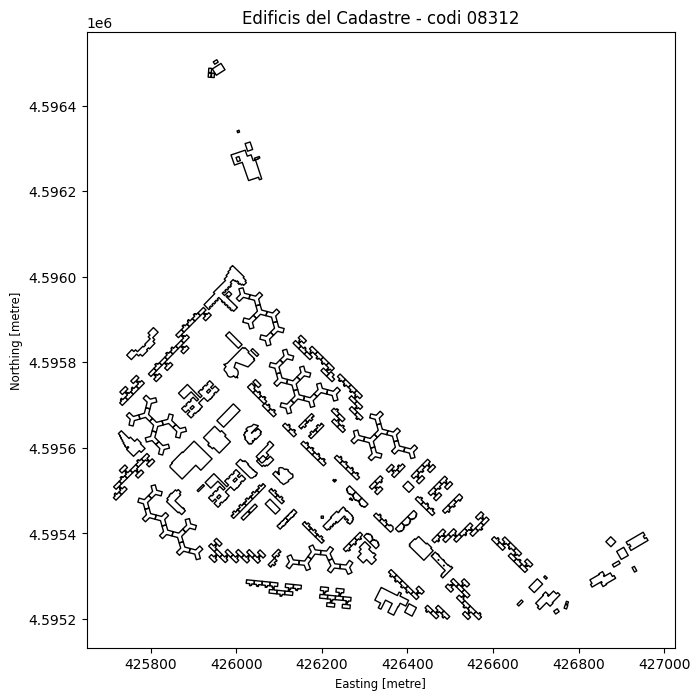

In [20]:
# Badia del Vallès
print("Extensió geogràfica:")
print(gdf_badia.total_bounds)

ax = gdf_badia.plot(
    figsize=(8,8),
    edgecolor="black",
    facecolor="none"
)

ax.set_title("Edificis del Cadastre - codi 08312")

In [21]:
# Badia del Vallès
url_municipis = (
    "https://maps.icgc.cat/vector01/rest/services/"
    "divisions_administratives_wms/MapServer/12/query"
)

params = {
    "where": "NOMMUNI = 'Badia del Vallès'",
    "outFields": "CODIMUNI,NOMMUNI,CODIPROV",
    "returnGeometry": "true",
    "outSR": 25831,
    "f": "geojson"
}

resposta_icgc = requests.get(url_municipis, params=params)
resultat = resposta_icgc.json()

municipi_badia = gpd.GeoDataFrame.from_features(
    resultat["features"],
    crs=25831
)

print(municipi_badia[["CODIMUNI","NOMMUNI","CODIPROV"]])

# Punt representatiu de cada edifici
punts_badia = gdf_badia.copy()
punts_badia["geometry"] = gdf_badia.geometry.representative_point()

# Comprovació que cada punt representatiu cau dins del municipi ICGC
punts_badia = gpd.sjoin(
    punts_badia,
    municipi_badia[["NOMMUNI","geometry"]],
    how="left",
    predicate="within"
)

print(punts_badia["NOMMUNI"].value_counts(dropna=False))

  CODIMUNI           NOMMUNI CODIPROV
0   089045  Badia del Vallès       08
NOMMUNI
Badia del Vallès    222
Name: count, dtype: int64


### Taula Control de Qualitat
Amb les dades obtingudes de Badia del Vallès.

Cada fila un municipi i cada columna un atribut o resultat.

Cada municipi serà a una concatenació a la taula de control.

In [22]:
registre_badia = {
    "municipi": "Badia del Vallès",
    "codi_ine": "08904",
    "codi_cataleg": "08312",
    "codi_icgc": "089045",
    "url": fila_badia["href_original"],
    "http_status": resposta.status_code,
    "zip_valid": True,
    "gml_llegit": True,
    "n_edificis": len(gdf_badia),
    "crs": str(gdf_badia.crs),
    "n_polygon": int((gdf_badia.geom_type == "Polygon").sum()),
    "n_multipolygon": int((gdf_badia.geom_type == "MultiPolygon").sum()),
    "n_dins": int(punts_badia["NOMMUNI"].notna().sum()),
    "percentatge_dins": (int(punts_badia["NOMMUNI"].notna().sum()) / len(gdf_badia))*100,
    "n_fora": int(punts_badia["NOMMUNI"].isna().sum()),
    "validacio": "Correcte",
    "observacions": "Tots els punts representatius dins del terme municipal"
}

df_validacio = pd.DataFrame([registre_badia])
df_validacio.T

,0
municipi,Badia del Vallès
codi_ine,08904
codi_cataleg,08312
codi_icgc,089045
url,https://www.catastro.hacienda.gob.es/INSPIRE/B...
http_status,200
zip_valid,True
gml_llegit,True
n_edificis,222
crs,EPSG:25831


## Descàrrega dels ZIP de cada municipi
En aquest cas, el request fa una petició de descàrrega, ja que sol·licita un arxiu .zip.

El servidor retorna el contingut binari del fitxer i queda emmagatzemat a `response`.

Es defineix un directori de desat de l'arxiu (el propi espai de Colab) i es desa el contingut de la petició (`response.content`).

In [ ]:
import requests
import zipfile
import io
import os

# URL de descàrrega del cadastre
url_gml = ("https://www.catastro.hacienda.gob.es/INSPIRE/""Buildings/08/08015-BADALONA/A.ES.SDGC.BU.08015.zip")

# Descàrrega
response = requests.get(url_gml)
response.raise_for_status()

# Desat del fitxer
zip_path = "/content/cadastre_badalona.zip"

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Descàrrega completada")
print("Mida:", round(len(response.content) / (1024**2), 2), "MB")

Descàrrega completada
Mida: 10.38 MB


## Inspecció dels arxius ZIP
Sense descompressió.

### Llibreries utilitzades
`zipfile`

`pygorio` : permet llegir i escriure dades geoespacials utilitzant GDAL/OGR (igual que `fiona`). En aquest cas, GeoPandas utilitza Pygorio com a motor de lectura.

`zipfile.ZipFile` permet obrir l'arxiu ZIP.

El mètode `.filelist`conté objectes tipus `ZipInfo` que representen els arxius inclosos dins del ZIP. D'aquests, es pot extreure informació com el nom o la mida.

`/vsizip/` és un sistema de fitxers virtuals de GDAL que permeten accedir al contingut d'un ZIP sense haver de descomprimir-lo.

In [ ]:
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for file in zip_ref.namelist():
        print(file)


with zipfile.ZipFile(zip_path, "r") as zip_ref:

    print("Fitxers continguts:")
    print(zip_ref.namelist())

    print("\nInformació dels fitxers:")

    for info in zip_ref.infolist():
        print(
            "Nom:", info.filename,
            "| Mida original:", info.file_size,
            "| Mida comprimida:", info.compress_size
        )

A.ES.SDGC.BU.08015.building.gml
A.ES.SDGC.BU.08015.buildingpart.gml
A.ES.SDGC.BU.08015.otherconstruction.gml
A.ES.SDGC.BU.MD.08015.xml
Fitxers continguts:
['A.ES.SDGC.BU.08015.building.gml', 'A.ES.SDGC.BU.08015.buildingpart.gml', 'A.ES.SDGC.BU.08015.otherconstruction.gml', 'A.ES.SDGC.BU.MD.08015.xml']

Informació dels fitxers:
Nom: A.ES.SDGC.BU.08015.building.gml | Mida original: 71486432 | Mida comprimida: 3944183
Nom: A.ES.SDGC.BU.08015.buildingpart.gml | Mida original: 175843682 | Mida comprimida: 6848697
Nom: A.ES.SDGC.BU.08015.otherconstruction.gml | Mida original: 1181915 | Mida comprimida: 83346
Nom: A.ES.SDGC.BU.MD.08015.xml | Mida original: 20007 | Mida comprimida: 3787


In [ ]:
import pyogrio
import geopandas as gpd

# Ruta al GML dins del ZIP, sense extracció
gml_building = (
    f"/vsizip/{zip_path}/A.ES.SDGC.BU.08015.building.gml"
)

# Inspecció de les capes disponibles
print("Capes disponibles:")
print(pyogrio.list_layers(gml_building))

# Inspecció dels 5 primers registres
buildings_sample = gpd.read_file(
    gml_building,
    engine="pyogrio",
    rows=5
)

print("\nColumnes:")
print(buildings_sample.columns.tolist())

print("\nPrimeres files:")
display(buildings_sample.drop(columns="geometry"))

Capes disponibles:
[['Building' 'Unknown']]

Columnes:
['gml_id', 'lowerCorner', 'upperCorner', 'beginLifespanVersion', 'conditionOfConstruction', 'beginning', 'end', 'endLifespanVersion', 'informationSystem', 'reference', 'localId', 'namespace', 'horizontalGeometryEstimatedAccuracy', 'horizontalGeometryEstimatedAccuracy_uom', 'horizontalGeometryReference', 'referenceGeometry', 'currentUse', 'numberOfBuildingUnits', 'numberOfDwellings', 'numberOfFloorsAboveGround', 'documentLink', 'format', 'sourceStatus', 'officialAreaReference', 'value', 'value_uom', 'geometry']

Primeres files:


,gml_id,lowerCorner,upperCorner,beginLifespanVersion,conditionOfConstruction,beginning,end,endLifespanVersion,informationSystem,reference,...,currentUse,numberOfBuildingUnits,numberOfDwellings,numberOfFloorsAboveGround,documentLink,format,sourceStatus,officialAreaReference,value,value_uom
0,ES.SDGC.BU.000400300DF38H,438087.647 4589392.139,438096.386 4589401.542,2007-04-23,functional,1933-01-01T00:00:00,1933-01-01T00:00:00,NaT,https://www1.sedecatastro.gob.es/CYCBienInmueb...,000400300DF38H,...,None,1,1,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,40,m2
1,ES.SDGC.BU.000400400DF38H,438083.3635 4589392.747,438101.532 4589413.306,2007-04-23,functional,1936-01-01T00:00:00,1936-01-01T00:00:00,NaT,https://www1.sedecatastro.gob.es/CYCBienInmueb...,000400400DF38H,...,None,1,1,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,73,m2
2,ES.SDGC.BU.000400500DF38H,438094.4045 4589401.1355,438115.055 4589424.245,2007-04-23,functional,1955-01-01T00:00:00,1955-01-01T00:00:00,NaT,https://www1.sedecatastro.gob.es/CYCBienInmueb...,000400500DF38H,...,None,1,0,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,421,m2
3,ES.SDGC.BU.000800100DF38H,437634.07445 4588904.3565,437696.5632 4588967.87125,2015-12-01,functional,1960-01-01T00:00:00,1960-01-01T00:00:00,NaT,https://www1.sedecatastro.gob.es/CYCBienInmueb...,000800100DF38H,...,3_industrial,1,0,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,2234,m2
4,ES.SDGC.BU.000800400DF38H,437757.891 4589042.4405,437829.257 4589115.571,2025-11-24,functional,1960-01-01T00:00:00,1960-01-01T00:00:00,NaT,https://www1.sedecatastro.gob.es/CYCBienInmueb...,000800400DF38H,...,4_3_publicServices,1,0,None,http://ovc.catastro.meh.es/OVCServWeb/OVCWcfLi...,jpeg,NotOfficial,grossFloorArea,2005,m2


#### TEST DE VALIDACIÓ AMB UN SEGON MUNICIPI
##### SANTA COLOMA DE CERVELLÓ (BADIA DEL VALLÈS)

Repetició de tot el procediment vist amb Badia del Vallès.

Estat HTTP: 200
Mida: 794490 bytes
Capçalera: b'PK\x03\x04'
Contingut del ZIP:
A.ES.SDGC.BU.08244.building.gml
A.ES.SDGC.BU.08244.buildingpart.gml
A.ES.SDGC.BU.08244.otherconstruction.gml
A.ES.SDGC.BU.MD.08244.xml
GML: A.ES.SDGC.BU.08244.building.gml
Mida: 6615206 bytes
Registres: 1429
CRS: EPSG:25831
Geometries: Polygon         1072
MultiPolygon     357
Name: count, dtype: int64
Camps: ['gml_id', 'lowerCorner', 'upperCorner', 'beginLifespanVersion', 'conditionOfConstruction', 'beginning', 'end', 'endLifespanVersion', 'informationSystem', 'reference', 'localId', 'namespace', 'horizontalGeometryEstimatedAccuracy', 'horizontalGeometryEstimatedAccuracy_uom', 'horizontalGeometryReference', 'referenceGeometry', 'currentUse', 'numberOfBuildingUnits', 'numberOfDwellings', 'numberOfFloorsAboveGround', 'documentLink', 'format', 'sourceStatus', 'officialAreaReference', 'value', 'value_uom', 'geometry']
Extensió geogràfica:
[ 416238.5784 4578759.7605  419802.5045 4581487.06  ]
  CODIMUNI         

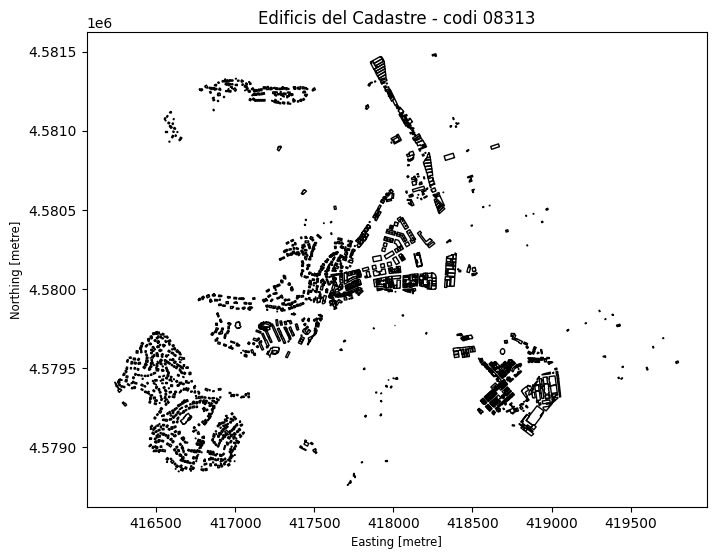

In [23]:
# Santa Coloma de Cervelló

import io
import zipfile

# Extracció de la informació del catàleg del municipi
fila_stacolomac = coincidencies[coincidencies["municipi"]=="Santa Coloma de Cervelló"].iloc[0]

resposta = requests.get(
    fila_stacolomac["href_original"],
    timeout=60
)

print("Estat HTTP:", resposta.status_code)
print("Mida:", len(resposta.content), "bytes")
print("Capçalera:", resposta.content[:4])


# Inspecció del ZIP
with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
  print("Contingut del ZIP:")
  for nom in z.namelist():
    print(nom)

import io
import zipfile

# Extracció del contingut del ZIP
with zipfile.ZipFile(io.BytesIO(resposta.content)) as z:
  nom_gml = [n for n in z.namelist() if n.endswith(".gml")][0]
  contingut_gml = z.read(nom_gml)

print("GML:", nom_gml)
print("Mida:", len(contingut_gml), "bytes")

import geopandas as gpd

with open("/content/santacolomacervello.gml", "wb") as f:
  f.write(contingut_gml)

gdf_stacolomac = gpd.read_file("/content/santacolomacervello.gml", engine="pyogrio")

print("Registres:", len(gdf_stacolomac))
print("CRS:", gdf_stacolomac.crs)
print("Geometries:", gdf_stacolomac.geom_type.value_counts())
print("Camps:", gdf_stacolomac.columns.tolist())

print("Extensió geogràfica:")
print(gdf_stacolomac.total_bounds)

ax = gdf_stacolomac.plot(
    figsize=(8,8),
    edgecolor="black",
    facecolor="none"
)

ax.set_title("Edificis del Cadastre - codi 08313")

url_municipis = (
    "https://maps.icgc.cat/vector01/rest/services/"
    "divisions_administratives_wms/MapServer/12/query"
)

params = {
    "where": "NOMMUNI = 'Santa Coloma de Cervelló'",
    "outFields": "CODIMUNI,NOMMUNI,CODIPROV",
    "returnGeometry": "true",
    "outSR": 25831,
    "f": "geojson"
}

resposta_icgc = requests.get(url_municipis, params=params)
resultat = resposta_icgc.json()

municipi_stacolomac = gpd.GeoDataFrame.from_features(
    resultat["features"],
    crs=25831
)

print(municipi_stacolomac[["CODIMUNI","NOMMUNI","CODIPROV"]])

# Punt representatiu de cada edifici
punts_stacolomac = gdf_stacolomac.copy()
punts_stacolomac["geometry"] = gdf_stacolomac.geometry.representative_point()

# Comprovació que cada punt representatiu cau dins del municipi ICGC
punts_stacolomac = gpd.sjoin(
    punts_stacolomac,
    municipi_stacolomac[["NOMMUNI","geometry"]],
    how="left",
    predicate="within"
)

print(punts_stacolomac["NOMMUNI"].value_counts(dropna=False))


                       gml_id       reference         localId  \
82  ES.SDGC.BU.08244A00800012  08244A00800012  08244A00800012   

                         geometry  
82  POINT (417956.046 4578912.41)  
Distància al límit (m): 30.012630532237786


Text(0.5, 1.0, 'Edifici fora del terme municipal – Santa Coloma de Cervelló')

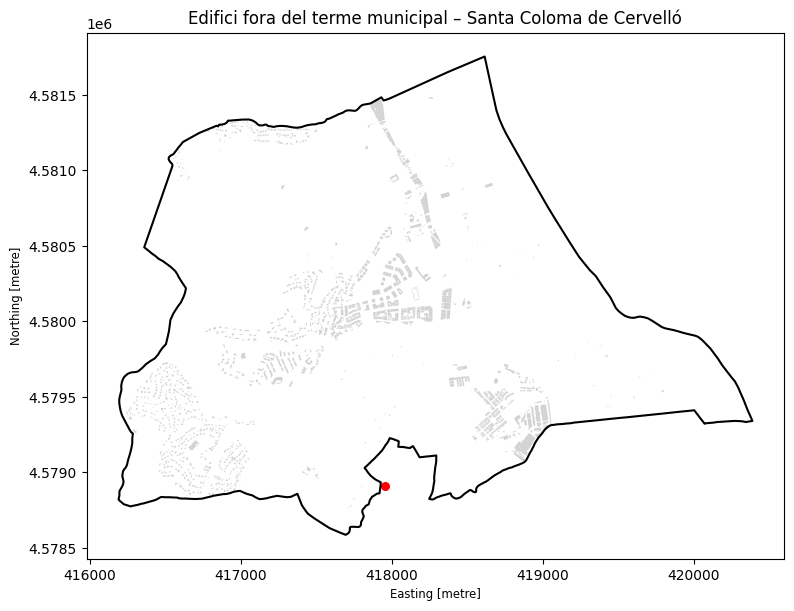

In [24]:
# Identifiquem l'edifici que ha quedat fora
edificis_fora = punts_stacolomac[
    punts_stacolomac["NOMMUNI"].isna()
]

print(
    edificis_fora[
        ["gml_id", "reference", "localId", "geometry"]
    ]
)

# Distància del punt representatiu al límit municipal
punt = edificis_fora.geometry.iloc[0]
limit_municipal = municipi_stacolomac.geometry.iloc[0].boundary

print("Distància al límit (m):", punt.distance(limit_municipal))

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 9))

municipi_stacolomac.boundary.plot(ax=ax, color="black")
gdf_stacolomac.plot(ax=ax, color="lightgrey", edgecolor="none")
edificis_fora.plot(ax=ax, color="red", markersize=30)

ax.set_title("Edifici fora del terme municipal – Santa Coloma de Cervelló")

In [29]:
# Actualitzacaió taula de control
registre_stacolomac = {
    "municipi": "Santa Coloma de Cervelló",
    "codi_ine": "08244",
    "codi_cataleg": "08244",
    "codi_icgc": "082444",
    "url": fila_stacolomac["href_original"],
    "http_status": resposta.status_code,
    "zip_valid": True,
    "gml_llegit": True,
    "n_edificis": len(gdf_stacolomac),
    "crs": str(gdf_stacolomac.crs),
    "n_polygon": int((gdf_stacolomac.geom_type == "Polygon").sum()),
    "n_multipolygon": int((gdf_stacolomac.geom_type == "MultiPolygon").sum()),
    "n_dins": int(punts_stacolomac["NOMMUNI"].notna().sum()),
    "percentatge_dins": (int(punts_stacolomac["NOMMUNI"].notna().sum()) / len(gdf_stacolomac))*100,
    "n_fora": int(punts_stacolomac["NOMMUNI"].isna().sum()),
    "validacio": "Correcte amb incidència",
    "observacions": "Tots els punts representatius menys 1 a 30 m dins del terme municipal"
}

df_validacio = pd.concat([df_validacio, pd.DataFrame([registre_stacolomac])], ignore_index=True)

df_validacio

,municipi,codi_ine,codi_cataleg,codi_icgc,url,http_status,zip_valid,gml_llegit,n_edificis,crs,n_polygon,n_multipolygon,n_dins,percentatge_dins,n_fora,validacio,observacions
0,Badia del Vallès,08904,08312,089045,https://www.catastro.hacienda.gob.es/INSPIRE/B...,200,True,True,222,EPSG:25831,212,10,222,100.000000,0,Correcte,Tots els punts representatius dins del terme m...
1,Santa Coloma de Cervelló,08244,08244,082444,https://www.catastro.hacienda.gob.es/INSPIRE/B...,200,True,True,1429,EPSG:25831,1072,357,1428,99.930021,1,Correcte,Tots els punts representatius menys 1 a 30 m d...
2,Santa Coloma de Cervelló,08244,08244,082444,https://www.catastro.hacienda.gob.es/INSPIRE/B...,200,True,True,1429,EPSG:25831,1072,357,1428,99.930021,1,Correcte amb incidència,Tots els punts representatius menys 1 a 30 m d...


In [26]:
resultat

{'type': 'FeatureCollection',
 'crs': {'type': 'name', 'properties': {'name': 'EPSG:25831'}},
 'features': [{'type': 'Feature',
   'geometry': {'type': 'Polygon',
    'coordinates': [[[418658.44519999996, 4581554.6249],
      [418615.0999999996, 4581753.800000001],
      [418371.61450000014, 4581650.9332],
      [418352.89329999965, 4581642.431399999],
      [418336.83609999996, 4581635.1395],
      [418061.43769999966, 4581510.0743],
      [418056.88210000005, 4581508.0055],
      [418035.9335000003, 4581498.4922],
      [418026.8152999999, 4581494.351399999],
      [418009.56799999997, 4581486.5189],
      [417984.8328999998, 4581475.2861],
      [417968.1634999998, 4581469.4428],
      [417958.6524, 4581466.1087],
      [417945.31790000014, 4581462.9662],
      [417931.29389999993, 4581483.750600001],
      [417860.70419999957, 4581443.9321],
      [417850.67090000026, 4581441.635399999],
      [417849.53670000006, 4581441.3758000005],
      [417848.0377000002, 4581441.0327],
      